# Book Recommendation System: Collaborative Filtering

## Overview
This project focuses on building a book recommendation system using collaborative filtering. Collaborative filtering is a technique used in recommendation systems to predict user preferences by collecting preferences from many users. The goal is to recommend books to users based on their past interactions and similarities with other users.

## Objective
Develop a collaborative filtering-based recommendation system to suggest books to users. The project will cover the complete pipeline, including data loading, exploratory data analysis, data preparation, model building, evaluation, and visualization.

## Learning Outcomes
1. Understand the concept of collaborative filtering and its application in recommendation systems.
2. Learn to preprocess and analyze user-item interaction data.
3. Gain experience in building a user-item matrix and computing user similarities.
4. Implement a recommendation system using cosine similarity.
5. Evaluate the recommendation system using metrics like Mean Squared Error (MSE).
6. Visualize user similarities and analyze the most recommended books.

---

## Step 1: Define the Problem
### Task:
Understand the problem and its real-world implications. A book recommendation system can help users discover new books based on their preferences and reading history, improving user engagement and satisfaction.

### Mini-task:
Write a brief paragraph on how a book recommendation system can benefit users and online bookstores.

---

A book recommendation system benefits users by providing personalized suggestions tailored to their interests, reading history, and preferences, making it easier to discover new books they are likely to enjoy. This enhances the overall user experience by saving time and offering relevant options, thereby increasing user satisfaction and engagement. For online bookstores, such systems drive sales by promoting books that align with customer tastes, encouraging repeat purchases, and fostering customer loyalty. Additionally, they help optimize inventory visibility and marketing strategies by highlighting books that may otherwise go unnoticed.

## Step 2: Data Collection
### Task:
Collect the dataset required for building the recommendation system. The dataset used in this project includes two files: `ratings.csv` and `books.csv`.

### Mini-task:
Load the dataset and inspect the first few rows to understand its structure.

#### Hint:
Use the `pandas` library to load the dataset and display the first 10 rows.

```python
import pandas as pd

# Load the dataset
ratings = pd.read_csv('ratings.csv')
books = pd.read_csv('books.csv')

# Display the first 10 rows of each dataset
### YOUR CODE HERE ###
```

---

In [74]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import scipy as sp # for numerical efficiency.

# Entity featurization and similarity computation
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import operator # item retrieval during iteration
import heapq # sorting of large lists

# Install dependencies as needed:
!pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Load ratings.csv
ratings_df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "zygmunt/goodbooks-10k",
  "ratings.csv"
)

# Load books.csv
books_df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "zygmunt/goodbooks-10k",
  "books.csv"
)

# print("First 5 records of ratings.csv:", ratings_df.head())
# print("First 5 records of books.csv:", books_df.head())

/tmp/ipython-input-74-3285688111.py:25: DeprecationWarning: load_dataset is deprecated and will be removed in a future version.
  ratings_df = kagglehub.load_dataset(
/tmp/ipython-input-74-3285688111.py:32: DeprecationWarning: load_dataset is deprecated and will be removed in a future version.
  books_df = kagglehub.load_dataset(


In [75]:
ratings_df.head()

,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


In [76]:
ratings_df.shape

(981756, 3)

In [77]:
# Limit the book rating to the first 1000 users
ratings_limited_df = ratings_df.head(1000)
ratings_limited_df.head()

,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


In [78]:
ratings_limited_df.shape

(1000, 3)

In [79]:
books_df.head()

,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,title,language_code,average_rating,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",eng,4.34,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,Harry Potter and the Sorcerer's Stone (Harry P...,eng,4.44,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,"Twilight (Twilight, #1)",en-US,3.57,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,To Kill a Mockingbird,eng,4.25,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,The Great Gatsby,eng,3.89,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


In [80]:
books_df.shape

(10000, 23)

In [81]:
# Limit also the book_df to the first 1000 users
books_limited_df = books_df.head(1000)
books_limited_df.head()

,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,title,language_code,average_rating,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",eng,4.34,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,Harry Potter and the Sorcerer's Stone (Harry P...,eng,4.44,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,"Twilight (Twilight, #1)",en-US,3.57,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,To Kill a Mockingbird,eng,4.25,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,The Great Gatsby,eng,3.89,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


In [82]:
books_limited_df.shape

(1000, 23)

In [83]:
books_limited_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         1000 non-null   int64  
 1   book_id                    1000 non-null   int64  
 2   best_book_id               1000 non-null   int64  
 3   work_id                    1000 non-null   int64  
 4   books_count                1000 non-null   int64  
 5   isbn                       977 non-null    object 
 6   isbn13                     979 non-null    float64
 7   authors                    1000 non-null   object 
 8   original_publication_year  998 non-null    float64
 9   original_title             980 non-null    object 
 10  title                      1000 non-null   object 
 11  language_code              971 non-null    object 
 12  average_rating             1000 non-null   float64
 13  ratings_count              1000 non-null   int64 

## Step 3: Exploratory Data Analysis (EDA)
### Task:
Analyze the dataset to understand the distribution of book ratings, identify popular books, and explore user behavior.

### Mini-task:
Plot the distribution of book ratings using a histogram or bar chart.

#### Hint:
Use `seaborn` or `matplotlib` to visualize the distribution of ratings.

```python
import seaborn as sns
import matplotlib.pyplot as plt

# Plot the distribution of book ratings
### YOUR CODE HERE ###
```

---

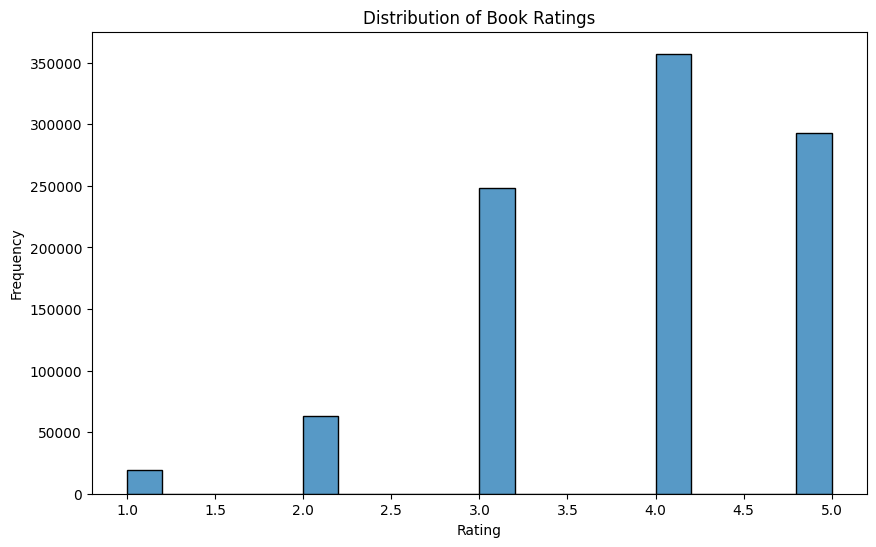

In [84]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the distribution of book ratings
plt.figure(figsize=(10, 6))
sns.histplot(ratings_df['rating'], bins=20)
plt.title('Distribution of Book Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

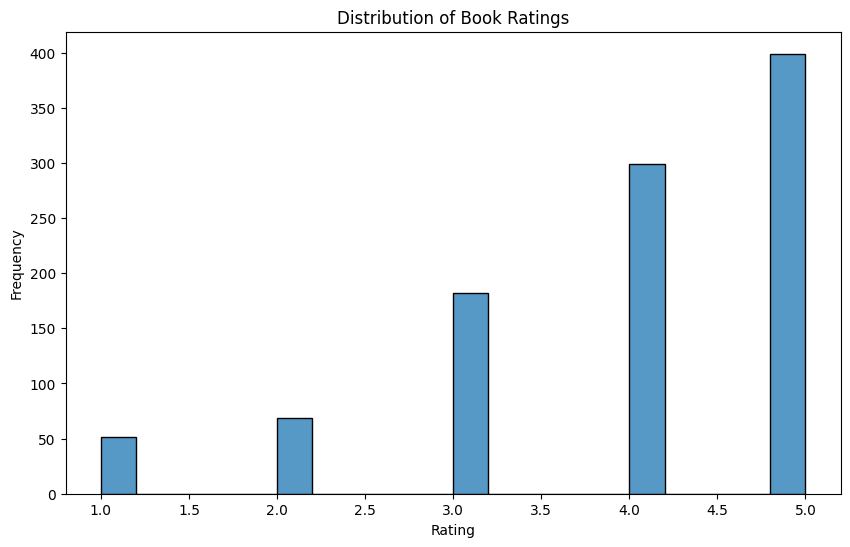

In [85]:
# Plot the distribution of book ratings for the first 1000 users
plt.figure(figsize=(10, 6))
sns.histplot(ratings_limited_df['rating'], bins=20)
plt.title('Distribution of Book Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

In [86]:
# Install dependencies as needed:
!pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "zygmunt/goodbooks-10k",
  "ratings.csv",
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head())

/tmp/ipython-input-86-602377763.py:7: DeprecationWarning: load_dataset is deprecated and will be removed in a future version.
  df = kagglehub.load_dataset(


First 5 records:    book_id  user_id  rating
0        1      314       5
1        1      439       3
2        1      588       5
3        1     1169       4
4        1     1185       4


In [87]:
df.shape

(981756, 3)

In [88]:
def fill_title(row):
  if pd.isna(row['original_title']):
    return row['title'].split('(')[0]
  elif pd.isna(row['original_title']) :
    return row['title']
  else:
    return row['original_title']

In [89]:
books_limited_df['original_title'] = books_limited_df.apply(fill_title, axis=1)

/tmp/ipython-input-89-159494718.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  books_limited_df['original_title'] = books_limited_df.apply(fill_title, axis=1)


In [90]:
books_limited_df.isnull().sum()

,0
id,0
book_id,0
best_book_id,0
work_id,0
books_count,0
isbn,23
isbn13,21
authors,0
original_publication_year,2
original_title,0


In [91]:
pd.set_option('display.max_columns', None)
books_limited_df[books_limited_df['language_code'].isna()]

,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,title,language_code,average_rating,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
44,45,4214,4214,1392700,264,770430074,9.780770e+12,Yann Martel,2001.0,Life of Pi,Life of Pi,NaN,3.88,1003228,1077431,42962,39768,74331,218702,384164,360466,https://images.gr-assets.com/books/1320562005m...,https://images.gr-assets.com/books/1320562005s...
131,132,3431,3431,2561472,123,1401308589,9.781401e+12,Mitch Albom,2003.0,The Five People You Meet in Heaven,The Five People You Meet in Heaven,NaN,3.90,449501,474699,16682,12360,33669,107800,155830,165040,https://s.gr-assets.com/assets/nophoto/book/11...,https://s.gr-assets.com/assets/nophoto/book/50...
203,204,5326,5326,3097440,2380,1561797464,9.781562e+12,Charles Dickens,1843.0,A Christmas Carol,A Christmas Carol,NaN,4.02,394540,441396,11568,6737,21415,93906,153823,165515,https://images.gr-assets.com/books/1406512317m...,https://images.gr-assets.com/books/1406512317s...
236,237,10592,10592,1552134,249,1416524304,9.781417e+12,Stephen King,1974.0,Carrie,Carrie,NaN,3.93,356814,377650,8264,4564,19479,96352,136054,121201,https://s.gr-assets.com/assets/nophoto/book/11...,https://s.gr-assets.com/assets/nophoto/book/50...
287,288,19691,19691,1112006,117,425172902,9.780425e+12,Tom Clancy,1984.0,The Hunt for Red October,"The Hunt for Red October (Jack Ryan Universe, #4)",NaN,4.01,270318,278255,2117,9470,13707,49906,95296,109876,https://images.gr-assets.com/books/1281995542m...,https://images.gr-assets.com/books/1281995542s...
320,321,10365,10365,115,69,375806814,9.780376e+12,Wilson Rawls,1961.0,Where the Red Fern Grows,Where the Red Fern Grows,NaN,4.04,268548,280179,8725,6585,15232,53560,89699,115103,https://images.gr-assets.com/books/1166154337m...,https://images.gr-assets.com/books/1166154337s...
408,409,9375,9375,2129359,94,375508414,9.780376e+12,Fannie Flagg,1987.0,Fried Green Tomatoes at the Whistle Stop Cafe,Fried Green Tomatoes at the Whistle Stop Cafe,NaN,4.26,207508,216286,4439,1259,4353,31358,79626,99690,https://s.gr-assets.com/assets/nophoto/book/11...,https://s.gr-assets.com/assets/nophoto/book/50...
412,413,7190,7190,1263212,1341,NaN,NaN,Alexandre Dumas,1844.0,Les Trois Mousquetaires,The Three Musketeers,NaN,4.06,195274,221481,4974,2176,8195,46090,83254,81766,https://images.gr-assets.com/books/1320436982m...,https://images.gr-assets.com/books/1320436982s...
464,465,14758,14758,964332,53,743495667,9.780743e+12,Jennifer Weiner,2002.0,In Her Shoes,In Her Shoes,NaN,3.78,167400,174338,2513,3345,11596,50482,64358,44557,https://images.gr-assets.com/books/1435252471m...,https://images.gr-assets.com/books/1435252471s...
486,487,7670,7670,997271,122,60541814,9.780061e+12,Michael Crichton,1969.0,The Andromeda Strain,The Andromeda Strain,NaN,3.87,173186,178917,2555,1599,9379,48894,69876,49169,https://s.gr-assets.com/assets/nophoto/book/11...,https://s.gr-assets.com/assets/nophoto/book/50...


In [92]:
books_limited_df[books_limited_df['isbn'].isna()]

,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,title,language_code,average_rating,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
105,106,9418327,9418327,14302659,48,NaN,NaN,Tina Fey,2011.0,Bossypants,Bossypants,eng,3.94,506250,609260,35142,14842,31761,129390,230080,203187,https://images.gr-assets.com/books/1481509554m...,https://images.gr-assets.com/books/1481509554s...
120,121,7604,7604,1268631,370,NaN,NaN,"Vladimir Nabokov, Craig Raine",1955.0,Lolita,Lolita,eng,3.88,469836,517990,18107,21091,37205,108664,165477,185553,https://images.gr-assets.com/books/1377756377m...,https://images.gr-assets.com/books/1377756377s...
161,162,49552,49552,3324344,675,NaN,NaN,"Albert Camus, Matthew Ward",1942.0,L’Étranger,The Stranger,eng,3.96,420600,483623,14836,10563,28920,100140,174957,169043,https://images.gr-assets.com/books/1349927872m...,https://images.gr-assets.com/books/1349927872s...
187,188,10664113,10664113,2936175,115,NaN,NaN,George R.R. Martin,2011.0,A Dance with Dragons,"A Dance with Dragons (A Song of Ice and Fire, #5)",eng,4.31,365954,424618,20072,2399,10150,53744,147136,211189,https://images.gr-assets.com/books/1327885335m...,https://images.gr-assets.com/books/1327885335s...
202,203,11505797,11505797,16441531,85,NaN,NaN,Jamie McGuire,2011.0,Beautiful Disaster,"Beautiful Disaster (Beautiful, #1)",eng,4.15,418309,442696,25298,17185,23298,61993,115123,225097,https://images.gr-assets.com/books/1358259032m...,https://images.gr-assets.com/books/1358259032s...
259,260,4865,4865,2370171,353,NaN,9.780672e+12,Dale Carnegie,1936.0,How to Win Friends and Influence People,How to Win Friends and Influence People,eng,4.13,282623,305437,7909,6734,13880,50529,94743,139551,https://images.gr-assets.com/books/1442726934m...,https://images.gr-assets.com/books/1442726934s...
323,324,16068905,16068905,21861351,80,NaN,NaN,Rainbow Rowell,2013.0,Fangirl,Fangirl,eng,4.12,340379,371730,39353,8626,16973,60097,121431,164603,https://images.gr-assets.com/books/1499565420m...,https://images.gr-assets.com/books/1499565420s...
347,348,16143347,16143347,21975829,77,NaN,NaN,E. Lockhart,2014.0,We Were Liars,We Were Liars,eng,3.85,273442,298780,36910,9074,22616,68468,102385,96237,https://images.gr-assets.com/books/1402749479m...,https://images.gr-assets.com/books/1402749479s...
412,413,7190,7190,1263212,1341,NaN,NaN,Alexandre Dumas,1844.0,Les Trois Mousquetaires,The Three Musketeers,NaN,4.06,195274,221481,4974,2176,8195,46090,83254,81766,https://images.gr-assets.com/books/1320436982m...,https://images.gr-assets.com/books/1320436982s...
463,464,1923820,1923820,6405906,1449,NaN,NaN,Anonymous,1611.0,Holy Bible: King James Version,Holy Bible: King James Version,eng,4.43,159457,171594,4438,10011,6802,11712,14338,128731,https://images.gr-assets.com/books/1313518530m...,https://images.gr-assets.com/books/1313518530s...


In [94]:
books_limited_df.dropna(subset=['original_publication_year', 'language_code', 'isbn', 'isbn13'], inplace=True)

/tmp/ipython-input-94-1184053884.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  books_limited_df.dropna(subset=['original_publication_year', 'language_code', 'isbn', 'isbn13'], inplace=True)


In [95]:
## Handling missing Values
missing_percentage = books_limited_df.isnull().sum() / len(books_limited_df) * 100
missing_percentage

,0
id,0.0
book_id,0.0
best_book_id,0.0
work_id,0.0
books_count,0.0
isbn,0.0
isbn13,0.0
authors,0.0
original_publication_year,0.0
original_title,0.0


In [96]:
books_limited_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 949 entries, 0 to 999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         949 non-null    int64  
 1   book_id                    949 non-null    int64  
 2   best_book_id               949 non-null    int64  
 3   work_id                    949 non-null    int64  
 4   books_count                949 non-null    int64  
 5   isbn                       949 non-null    object 
 6   isbn13                     949 non-null    float64
 7   authors                    949 non-null    object 
 8   original_publication_year  949 non-null    float64
 9   original_title             949 non-null    object 
 10  title                      949 non-null    object 
 11  language_code              949 non-null    object 
 12  average_rating             949 non-null    float64
 13  ratings_count              949 non-null    int64  
 14 

In [98]:
##Handling Duplicates
duplicates = books_limited_df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates}")


Number of duplicate rows: 0


In [100]:
print (f'Number of ratings in dataset: {ratings_limited_df.shape[0]}')

Number of ratings in dataset: 1000


## Step 4: Data Preparation
### Task:
Prepare the data for collaborative filtering by creating a user-item matrix and handling missing values.

### Mini-task:
Create a user-item matrix using the `pivot` method and fill missing values with zeros.

#### Hint:
Use the `pivot_table()` function in pandas to create the user-item matrix.

```python
# Create a user-item matrix
### YOUR CODE HERE ###
```

---

In [101]:
# Create a user-item matrix
util_matrix = ratings_limited_df.pivot_table(index=['user_id'],
                                       columns=['book_id'],
                                       values='rating')
util_matrix.shape

(288, 10)

## Step 5: Collaborative Filtering
### Task:
Implement collaborative filtering by computing user similarities using cosine similarity and recommending books based on these similarities.

### Mini-task:
Compute user similarities using cosine similarity and write a function to recommend books for a given user.

#### Hint:
Use `cosine_similarity` from `sklearn.metrics.pairwise` to compute user similarities.

```python
from sklearn.metrics.pairwise import cosine_similarity

# Compute user similarities
### YOUR CODE HERE ###

# Write a function to recommend books for a given user
### YOUR CODE HERE ###
```

---

In [103]:
# Fill Nan values with 0's, transpose matrix, and drop users with no ratings
util_matrix.fillna(0, inplace=True)
util_matrix = util_matrix.T
util_matrix = util_matrix.loc[:, (util_matrix != 0).any(axis=0)]

In [105]:
# Compute the similarity matrix using the cosine similarity metric
user_similarity = cosine_similarity(util_matrix.T)

In [106]:
def collab_generate_top_N_recommendations(user, N=10, k=20):
    # Cold-start problem - no ratings given by the reference user.
    # With no further user data, we solve this by simply recommending
    # the top-N most popular books in the item catalogue.
    if user not in user_similarity:
        return ratings_limited_df.groupby('book_id').mean().sort_values(by='rating',
                                        ascending=False).index[:N].to_list()

    # Gather the k users which are most similar to the reference user
    sim_users = user_similarity.sort_values(by=user, ascending=False).index[1:k+1]
    favorite_user_items = [] # <-- List of highest rated items gathered from the k users
    most_common_favorites = {} # <-- Dictionary of highest rated items in common for the k users

    for i in sim_users:
        # Maximum rating given by the current user to an item
        max_score = util_matrix_norm.loc[:, i].max()
        # Save the names of items maximally rated by the current user
        favorite_user_items.append(util_matrix[util_matrix.loc[:, i]==max_score].index.tolist())

    # Loop over each user's favourite items and tally which ones are
    # most popular overall.
    for item_collection in range(len(favorite_user_items)):
        for item in favorite_user_items[item_collection]:
            if item in most_common_favorites:
                most_common_favorites[item] += 1
            else:
                most_common_favorites[item] = 1
    # Sort the overall most popular items and return the top-N instances
    sorted_list = sorted(most_common_favorites.items(), key=operator.itemgetter(1), reverse=True)[:N]
    top_N = [x[0] for x in sorted_list]
    return top_N

## Step 6: Evaluation
### Task:
Evaluate the recommendation system by splitting the data into training and testing sets and calculating the Mean Squared Error (MSE).

### Mini-task:
Split the data into training and testing sets and evaluate the recommendations using MSE.

#### Hint:
Use `train_test_split` from `sklearn.model_selection` to split the data and `mean_squared_error` from `sklearn.metrics` to calculate MSE.

```python
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Split the data into training and testing sets
### YOUR CODE HERE ###

# Evaluate the recommendations using MSE
### YOUR CODE HERE ###
```

---

In [107]:
# Splitting the dataset into features (X) and target (y)
# We will use the limited_ratings DataFrame for splitting
X = books_limited_df
y = ratings_limited_df

In [108]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (949, 23)
y shape: (1000, 3)


In [118]:
cols_to_drop = [
    'id', 'book_id', 'best_book_id', 'work_id', 'isbn', 'isbn13',
    'authors', 'original_title', 'title', 'language_code',
    'image_url', 'small_image_url', 'average_rating'
]

# Drop only columns that exist in df
existing_cols_to_drop = [col for col in cols_to_drop if col in ratings_limited_df.columns]
X = ratings_limited_df.drop(columns=existing_cols_to_drop)
X.shape

(1000, 2)

In [119]:
X

,user_id,rating
0,314,5
1,439,3
2,588,5
3,1169,4
4,1185,4
...,...,...
995,50999,5
996,51166,3
997,51838,4
998,52036,4


In [120]:
y = ratings_limited_df['rating']
y.shape

(1000,)

In [121]:
# Splitting into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [122]:
# Initializing and training the linear regression model

from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [123]:
# Making predictions on the test set
y_pred = lr.predict(X_test)

In [124]:
y_pred

array([4., 5., 4., 4., 5., 4., 2., 5., 3., 4., 4., 5., 4., 4., 1., 5., 4.,
       4., 4., 5., 5., 5., 5., 1., 4., 5., 4., 5., 2., 4., 5., 5., 5., 5.,
       5., 3., 3., 5., 5., 5., 5., 1., 5., 5., 5., 3., 5., 5., 5., 4., 5.,
       3., 4., 5., 4., 5., 4., 5., 1., 1., 3., 4., 3., 2., 5., 5., 1., 5.,
       5., 5., 1., 5., 5., 5., 5., 5., 5., 5., 3., 5., 4., 5., 3., 5., 3.,
       4., 4., 3., 2., 3., 5., 4., 5., 3., 4., 2., 4., 5., 5., 3., 3., 3.,
       5., 3., 5., 3., 4., 5., 4., 5., 1., 3., 4., 2., 4., 4., 3., 5., 5.,
       5., 2., 5., 5., 2., 1., 5., 5., 5., 3., 3., 5., 5., 1., 5., 5., 4.,
       5., 1., 5., 3., 4., 3., 4., 2., 5., 2., 4., 4., 3., 5., 5., 4., 3.,
       4., 5., 4., 5., 5., 5., 3., 5., 5., 5., 3., 3., 4., 1., 2., 4., 4.,
       4., 2., 2., 5., 5., 5., 1., 1., 1., 5., 2., 2., 5., 4., 3., 1., 5.,
       5., 4., 5., 3., 5., 5., 5., 3., 5., 5., 5., 4., 3.])

In [125]:
# Calculating evaluation metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [126]:
print("\nModel Evaluation:")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R-squared (R2): {r2:.2f}")


Model Evaluation:
Mean Squared Error (MSE): 0.00
Mean Absolute Error (MAE): 0.00
R-squared (R2): 1.00


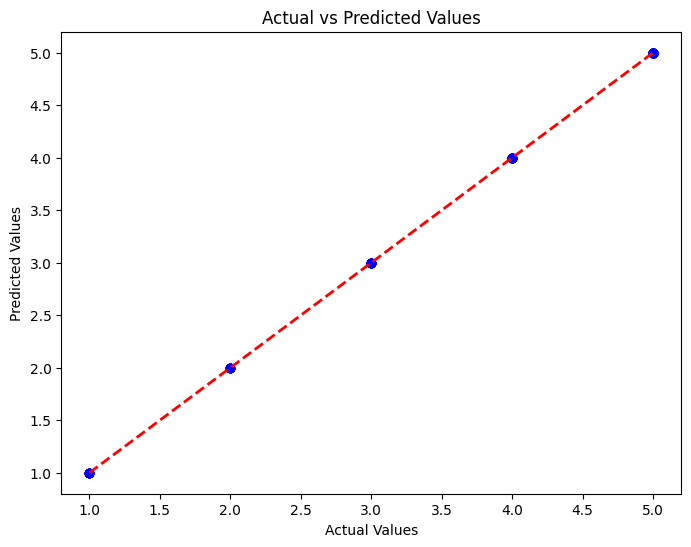

In [127]:
# Plotting actual vs predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='b')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2)
plt.title("Actual vs Predicted Values")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.show()

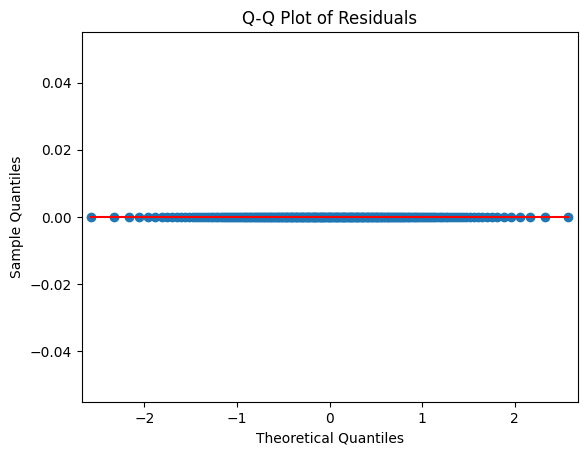

In [128]:
# Calculate residuals
residuals = y_test - y_pred

# Create a Q-Q plot of the residuals
sm.qqplot(residuals, line='s')  # 'line' argument for a standardized line
plt.title("Q-Q Plot of Residuals")
plt.show()

## Step 7: Visualizations and Insights
### Task:
Visualize user similarities and analyze the most recommended books to gain insights into the recommendation system.

### Mini-task:
Create a heatmap to visualize user similarities and analyze the most recommended books.

#### Hint:
Use `seaborn.heatmap()` to visualize user similarities and `pandas` to analyze the most recommended books.

```python
# Create a heatmap to visualize user similarities
### YOUR CODE HERE ###

# Analyze the most recommended books
### YOUR CODE HERE ###
```

---

Text(0.5, 1.0, 'Books Utility Matrix')

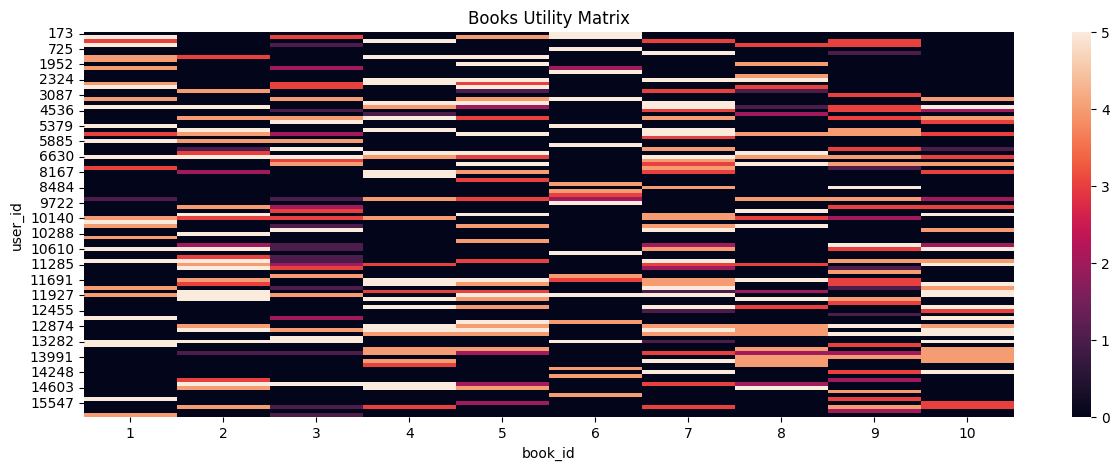

In [134]:
fig, ax = plt.subplots(figsize=(15,5))
# We select only the first 100 users for ease of computation and visualisation.
sns.heatmap(util_matrix[:100], annot=False, ax=ax).set_title('Books Utility Matrix')

In [135]:
# Our recommended list for user 314
collab_generate_top_N_recommendations(314)

[4, 1, 2, 10, 6, 7, 5, 8, 9, 3]

In [136]:
# User 314's historical ratings
ratings_df[ratings_df['user_id'] == 314][:][['book_id','rating']].sort_values(by='rating', ascending=False)[:10]

,book_id,rating
0,1,5
501,6,5
3000,31,5
4600,47,5
10200,103,5
14001,141,5
321638,3220,5
293182,2935,5
267008,2673,5
21400,215,5


In [137]:
title = "The Lord of the Rings: Weapons and Warfare"
actual_rating = ratings_df[(ratings_df['user_id'] == 314) & (ratings_df['book_id'] == title)]['rating']
y_pred = lr.predict(X_test)

print (f"Title - {title}")
print ("---")
print (f"Actual rating: \t\t {X_test}")
print (f"Predicted rating: \t {y_pred}")

Title - The Lord of the Rings: Weapons and Warfare
---
Actual rating: 		      user_id  rating
521    15318       4
737    19729       5
740    20782       4
660    22164       4
411     5461       5
..       ...     ...
408     3739       5
332    17643       5
208     5272       5
613     6634       4
78     39423       3

[200 rows x 2 columns]
Predicted rating: 	 [4. 5. 4. 4. 5. 4. 2. 5. 3. 4. 4. 5. 4. 4. 1. 5. 4. 4. 4. 5. 5. 5. 5. 1.
 4. 5. 4. 5. 2. 4. 5. 5. 5. 5. 5. 3. 3. 5. 5. 5. 5. 1. 5. 5. 5. 3. 5. 5.
 5. 4. 5. 3. 4. 5. 4. 5. 4. 5. 1. 1. 3. 4. 3. 2. 5. 5. 1. 5. 5. 5. 1. 5.
 5. 5. 5. 5. 5. 5. 3. 5. 4. 5. 3. 5. 3. 4. 4. 3. 2. 3. 5. 4. 5. 3. 4. 2.
 4. 5. 5. 3. 3. 3. 5. 3. 5. 3. 4. 5. 4. 5. 1. 3. 4. 2. 4. 4. 3. 5. 5. 5.
 2. 5. 5. 2. 1. 5. 5. 5. 3. 3. 5. 5. 1. 5. 5. 4. 5. 1. 5. 3. 4. 3. 4. 2.
 5. 2. 4. 4. 3. 5. 5. 4. 3. 4. 5. 4. 5. 5. 5. 3. 5. 5. 5. 3. 3. 4. 1. 2.
 4. 4. 4. 2. 2. 5. 5. 5. 1. 1. 1. 5. 2. 2. 5. 4. 3. 1. 5. 5. 4. 5. 3. 5.
 5. 5. 3. 5. 5. 5. 4. 3.]



## Considerations
**What are some key takeaways you learned from this project?**
- Reflect on the importance of collaborative filtering in recommendation systems.
- Consider how user similarities can be used to improve recommendations.

**How would you share your findings with a team?**
- Prepare a presentation with visualizations and key insights.
- Discuss the impact of user similarities on book recommendations.

**What would you share with and recommend to stakeholders?**
- Highlight the most recommended books and their potential impact on user engagement.
- Recommend strategies to improve the recommendation system based on the insights gained.

I was able to streamline a large data into a more concise form by using the collaborative filtering within to extract useful insight from the data and this aided me to further process the data to get the required recommendation.
The impact of user similarities on book recommendations is to introduce the best way to filter, group and extract books that are similar.
